# Мягкий малый ранг

В основной модели все наклоны лежат строго в подпространстве индексов: $b_i=P^\top\ell_i$. Здесь разрешаем каждому индивиду небольшое собственное отклонение:
$$
b_i=P^\top\ell_i+\delta_i,\qquad P\delta_i=0 .
$$
Вместо ограничения $\delta_i=0$ штрафуем за отклонения, $\Pi=I-P^\top P$:
$$
S_\kappa=\sum_i\|M_F(Y_i-X_ib_i)\|^2+\kappa\sum_i b_i^\top\Pi b_i,\qquad
\hat b_i(\kappa)=(\hat G_i^F+\kappa\Pi)^{-1}Z_i^F .
$$
При $\kappa=0$ это МНК по каждому индивиду, при $\kappa=\infty$ — жёсткий малый ранг.

**Что утверждает теорема (известные $P$ и $F$):**
- (a) риск $\mathcal R(\kappa)=\kappa^2\|G_\kappa^{-1}\delta\|^2+\sigma^2\operatorname{tr}(G_\kappa^{-1}GG_\kappa^{-1})$ и $\mathcal R'(0)=-2\sigma^2\operatorname{tr}(\Pi G^{-2}\Pi)<0$: небольшое $\kappa>0$ всегда лучше МНК;
- (b) если $\delta_i$ случайны с ковариацией $\tau^2\Pi$, то $\kappa_0=\sigma^2/\tau^2$ даёт наименьший риск $\sigma^2\operatorname{tr}(G+\kappa_0\Pi)^{-1}$ среди всех линейных оценок, точных на подпространстве индексов, — и строго лучше МНК и жёсткой оценки;
- (c) при $G=gI$: $\mathcal R(\kappa^*)=\sigma^2m/g+VD/(V+D)\le\min(\mathcal R_{\rm МНК},\mathcal R_{\rm жёсткая})$, где $V=\sigma^2(d-m)/g$, $D=\|\delta\|^2$.

$\kappa$ выбирается эмпирическим Байесом: $\mathsf E\|\Pi\hat b_i^{\rm ols}\|^2=\tau^2(d-m)+\sigma^2\operatorname{tr}(\Pi G_i^{-1})$.

**План:** 1) численно проверить формулы теоремы; 2–3) синтетика с оценёнными $P$ и $F$; 4) монотонность алгоритма; 5) данные Dominick's.

Код моделей: `panelfac.py` (полная панель), `panelmiss.py` (панель с пропусками), `panelsoft.py` (мягкий малый ранг) — рядом с ноутбуком.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import panelfac as pf
import panelmiss as pm
import panelsoft as ps

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
C_OLS, C_HARD, C_SOFT, C_OR = '#8a8f98', '#1d5fbf', '#c8500a', '#222222'

## 1. Проверка теоремы при известных $P$ и $F$

Один индивид, $d=12$, $m=2$, $T=60$, признаки коррелированы и имеют разный масштаб, так что $G$ далека от изотропной.

R'(0): численно -0.054628, формула -2 s^2 tr(Pi G^-2 Pi) = -0.054628
МНК: формула 0.4504, МК 0.4491
argmin по сетке 43.5, теория kappa0 = s^2/tau^2 = 44.4


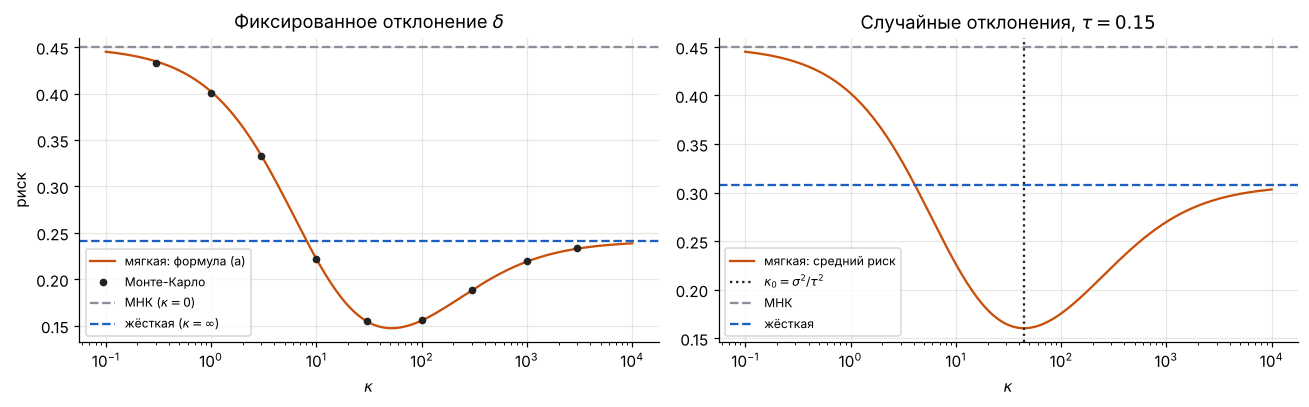

In [2]:
rng = np.random.default_rng(1)
d, m, T, sigma = 12, 2, 60, 1.0
P = np.linalg.qr(rng.normal(size=(d, m)))[0].T            # индексы: m x d, ортонормированные строки
Q = ps.complement(P)                                         # Pi = I - P^T P
S = 0.5 ** np.abs(np.subtract.outer(np.arange(d), np.arange(d)))
X = rng.normal(size=(T, d)) @ np.linalg.cholesky(S).T * np.linspace(0.5, 2, d)
X -= X.mean(0)                                               # проекция на константу (факторов нет)
G = X.T @ X
Gi = np.linalg.inv(G)

ell = np.array([1.5, -0.7]); delta = Q @ rng.normal(size=d) * 0.15
b = P.T @ ell + delta

# (a) фиксированное отклонение: формула риска против Монте-Карло
kgrid = np.geomspace(0.1, 1e4, 200)
R_formula = [ps.risk_fixed(G, P, delta, sigma ** 2, k) for k in kgrid]
R_ols, R_hard = ps.risk_fixed(G, P, delta, sigma ** 2, 0.0), ps.risk_fixed(G, P, delta, sigma ** 2, np.inf)
Zs = (X @ b + sigma * rng.normal(size=(20000, T))) @ X        # 20000 повторов шума
kmc = [0.3, 1, 3, 10, 30, 100, 300, 1000, 3000]
R_mc = [np.mean(np.sum((np.linalg.solve(G + k * Q, Zs.T).T - b) ** 2, 1)) for k in kmc]
h = 1e-5
print(f"R'(0): численно {(ps.risk_fixed(G, P, delta, sigma**2, h) - R_ols) / h:.6f}, "
      f"формула -2 s^2 tr(Pi G^-2 Pi) = {-2 * sigma**2 * np.trace(Q @ Gi @ Gi @ Q):.6f}")
print(f'МНК: формула {R_ols:.4f}, МК {np.mean(np.sum((np.linalg.solve(G, Zs.T).T - b) ** 2, 1)):.4f}')

# (b) случайные отклонения delta ~ (0, tau^2 Pi)
tau = 0.15; k0 = sigma ** 2 / tau ** 2
rho = [ps.risk_bayes(G, P, sigma ** 2, tau ** 2, k) for k in kgrid]
rho_ols, rho_hard = ps.risk_bayes(G, P, sigma**2, tau**2, 0.0), ps.risk_bayes(G, P, sigma**2, tau**2, np.inf)
print(f'argmin по сетке {kgrid[np.argmin(rho)]:.1f}, теория kappa0 = s^2/tau^2 = {k0:.1f}')

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axs[0]
ax.plot(kgrid, R_formula, color=C_SOFT, label='мягкая: формула (a)')
ax.plot(kmc, R_mc, 'o', color=C_OR, ms=4, label='Монте-Карло')
ax.axhline(R_ols, color=C_OLS, ls='--', label='МНК ($\\kappa=0$)'); ax.axhline(R_hard, color=C_HARD, ls='--', label='жёсткая ($\\kappa=\\infty$)')
ax.set_xscale('log'); ax.set_xlabel('$\\kappa$'); ax.set_ylabel('риск'); ax.set_title('Фиксированное отклонение $\\delta$')
ax.legend(fontsize=8)
ax = axs[1]
ax.plot(kgrid, rho, color=C_SOFT, label='мягкая: средний риск')
ax.axvline(k0, color=C_OR, ls=':', label='$\\kappa_0=\\sigma^2/\\tau^2$')
ax.axhline(rho_ols, color=C_OLS, ls='--', label='МНК'); ax.axhline(rho_hard, color=C_HARD, ls='--', label='жёсткая')
ax.set_xscale('log'); ax.set_xlabel('$\\kappa$'); ax.set_title('Случайные отклонения, $\\tau=0.15$')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Тождество Пифагора из части (b):** для любой линейной оценки $KZ$, точной на подпространстве индексов ($KGP^\top=P^\top$), $\mathsf E\|KZ-b\|^2=\sigma^2\operatorname{tr}(G+\kappa_0\Pi)^{-1}+\mathsf E\|KZ-\hat b(\kappa_0)\|^2$. Проверяем обе части по формулам и средний риск по Монте-Карло.

In [3]:
A0inv = np.linalg.inv(G + k0 * Q)
rho0 = ps.risk_bayes(G, P, sigma ** 2, tau ** 2, k0)
rows = []
for name, kap in [('МНК', 0.0), ('жёсткая', np.inf), ('мягкая, 3 kappa0', 3 * k0), ('мягкая, kappa0', k0)]:
    K = ps.shrink_matrix(G, P, kap); D = K - A0inv
    gap = tau ** 2 * np.trace(D @ G @ Q @ G @ D.T) + sigma ** 2 * np.trace(D @ G @ D.T)
    rows.append([name, ps.risk_bayes(G, P, sigma ** 2, tau ** 2, kap), rho0 + gap])
# Монте-Карло: случайные l, delta, eps
R = 20000
bb = rng.normal(size=(R, m)) * 3 @ P + (rng.normal(size=(R, d)) * tau) @ Q
Zm = (bb @ X.T + sigma * rng.normal(size=(R, T))) @ X
for row, kap in zip(rows, [0.0, np.inf, 3 * k0, k0]):
    row.append(np.mean(np.sum(((ps.shrink_matrix(G, P, kap) @ Zm.T).T - bb) ** 2, 1)))
pd.DataFrame(rows, columns=['оценка', 'риск по формуле', 'sigma^2 tr(G_k0^-1) + E||KZ - b(k0)||^2', 'Монте-Карло']).set_index('оценка').round(4)

,риск по формуле,sigma^2 tr(G_k0^-1) + E||KZ - b(k0)||^2,Монте-Карло
оценка,,,
МНК,0.4504,0.4504,0.4505
жёсткая,0.3079,0.3079,0.3095
"мягкая, 3 kappa0",0.1862,0.1862,0.1870
"мягкая, kappa0",0.1603,0.1603,0.1608


**Изотропный случай (c) и эмпирический Байес.** При $G=gI$ сравниваем точный минимум с формулой $\sigma^2m/g+VD/(V+D)$. Затем проверяем оценку $\tau^2$ по 2000 индивидам с разными неизотропными $G_i$.

In [4]:
g = 50.0; Gs = g * np.eye(d); V = sigma ** 2 * (d - m) / g
rows = []
for Dv in [0.05, 0.36, 2.0]:
    dl = Q @ rng.normal(size=d); dl *= np.sqrt(Dv) / np.linalg.norm(dl)
    kk = np.geomspace(1e-2, 1e5, 3000)
    rr = [ps.risk_fixed(Gs, P, dl, sigma ** 2, k) for k in kk]
    rows.append([Dv, V, sigma**2 * (d - m) / Dv, kk[np.argmin(rr)], min(rr), sigma**2 * m / g + V * Dv / (V + Dv),
                 sigma**2 * d / g, sigma**2 * m / g + Dv])
display(pd.DataFrame(rows, columns=['D', 'V', 'kappa* формула', 'kappa* сетка', 'мин. риск сетка', 'мин. риск формула',
                                    'риск МНК', 'риск жёсткой']).round(4))

n_eb = 2000; qn = []; trs = []
for i in range(n_eb):
    Xi = rng.normal(size=(T, d)) @ np.linalg.cholesky(S).T * rng.uniform(0.5, 2, d); Xi -= Xi.mean(0)
    Gi_ = Xi.T @ Xi
    bi = P.T @ rng.normal(size=m) * 2 + Q @ rng.normal(size=d) * tau
    bo = np.linalg.solve(Gi_, Xi.T @ (Xi @ bi + sigma * rng.normal(size=T)))
    qn.append(np.sum((Q @ bo) ** 2)); trs.append(np.trace(Q @ np.linalg.inv(Gi_)))
print(f'tau^2 = {tau**2:.5f}, оценка эмпирического Байеса {max(0, np.mean(qn) - sigma**2 * np.mean(trs)) / (d - m):.5f}')

,D,V,kappa* формула,kappa* сетка,мин. риск сетка,мин. риск формула,риск МНК,риск жёсткой
0,0.05,0.2,200.0000,200.3398,0.0800,0.0800,0.24,0.09
1,0.36,0.2,27.7778,27.7213,0.1686,0.1686,0.24,0.40
2,2.00,0.2,5.0000,4.9915,0.2218,0.2218,0.24,2.04


tau^2 = 0.02250, оценка эмпирического Байеса 0.02213


**Оценка $\tau^2$ по двум половинам ряда.** Обычный эмпирический Байес опирается на формулу $\operatorname{Var}\hat b_i^{\rm ols}=\sigma^2G_i^{-1}$. Если она неверна (автокорреляция или гетероскедастичность шума), лишний шум принимается за настоящие отклонения. Другая оценка: МНК-наклоны $\hat b_i^{(1)}$, $\hat b_i^{(2)}$ по первой и второй половинам ряда. Если шум в половинах не коррелирован, то $\mathsf E\langle\Pi\hat b_i^{(1)},\Pi\hat b_i^{(2)}\rangle=\tau^2(d-m)$, и формула для дисперсии не нужна. Сравним обе оценки при автокоррелированных признаках (AR(1), $\rho_x=0.7$) и шуме AR(1) с $\rho_\varepsilon\in\{0,\,0.6\}$; $n=200$, $T=100$, $d=20$, $m=2$, 10 повторений.

In [5]:
rows = []
for tau_ in [0.0, 0.1]:
    for re in [0.0, 0.6]:
        r_ = np.array([ps.tau2_demo(tau_, re, seed=s) for s in range(10)])
        rows.append([tau_ ** 2, re, r_[:, 0].mean(), r_[:, 0].std(), r_[:, 1].mean(), r_[:, 1].std()])
pd.DataFrame(rows, columns=['истинное tau^2', 'rho шума', 'ЭБ: среднее', 'ЭБ: ст. откл.', 'половины: среднее', 'половины: ст. откл.']).round(4)

,истинное tau^2,rho шума,ЭБ: среднее,ЭБ: ст. откл.,половины: среднее,половины: ст. откл.
0,0.00,0.0,0.0003,0.0003,0.0005,0.0007
1,0.00,0.6,0.0133,0.0006,0.0006,0.0006
2,0.01,0.0,0.0103,0.0007,0.0103,0.0013
3,0.01,0.6,0.0233,0.0007,0.0105,0.0009


**Итог проверки.** Формула риска совпадает с Монте-Карло, $\mathcal R'(0)$ — до шестого знака. Минимум среднего риска стоит в $\kappa_0=\sigma^2/\tau^2$ (на сетке 43.5 при теоретическом 44.4), тождество Пифагора выполняется точно, а при $G=gI$ минимум совпадает с $\sigma^2m/g+VD/(V+D)$. Эмпирический Байес восстанавливает $\tau^2$ (0.0221 при истинном 0.0225). При автокоррелированном шуме обычная оценка находит отклонения там, где их нет (0.0133 при $\tau^2=0$). Оценка по половинам остаётся несмещённой ценой примерно вдвое большего разброса.

## 2. Синтетика: размер отклонений $\tau$

Данные как в основном ноутбуке ($n=100$, $T=100$, $d=20$, $m=r=2$, связь признаков с факторами $0.5$), но $b_i=P^\top\ell_i+\delta_i$ с $\delta_i\sim N(0,\tau^2\Pi)$. Для масштаба: $\|P^\top\ell_i\|\approx1.9$, а $\mathsf E\|\delta_i\|=\tau\sqrt{18}$, то есть при $\tau=0.1$ отклонение около $0.42$.

Сравниваем (20 повторений, ошибка $\|\hat{\mathcal B}-\mathcal B\|_F/\|\mathcal B\|_F$):
- **МНК + факторы** — мягкий алгоритм с $\kappa=0$ (свои наклоны у каждого индивида, факторы оцениваются);
- **жёсткая** — основной метод ($\kappa=\infty$);
- **мягкая (ЭБ)** — $\kappa$ эмпирическим Байесом, $P$ и $F$ оцениваются;
- **оракул** — мягкая оценка при истинных $P$, $F$ и $\kappa_0=\sigma^2/\tau^2$;
- **теория** — $\sqrt{\sum_i\rho_i}/\|\mathcal B\|_F$, где $\rho_i$ — средний риск из теоремы при истинных $P$, $F$ (для трёх оценок).

In [6]:
def one(tau, seed, T=100, n=100):
    D = ps.make_soft_data(tau, n=n, T=T, seed=seed)
    Y, X = D['Y'], D['X']
    H = pf.fit(Y, X, 2, 2)                                   # жёсткая оценка
    Sft = ps.fit_soft(Y, X, 2, 2, 'eb', hard=H)              # мягкая, kappa эмпирическим Байесом
    O = ps.fit_soft(Y, X, 2, 2, 0.0, hard=H)                 # МНК + факторы
    k0 = D['sigma'] ** 2 / tau ** 2 if tau > 0 else np.inf
    Bor, Gt = ps.oracle_soft(D, k0)
    nb = np.linalg.norm(D['B'])
    th = [np.sqrt(ps.risk_bayes(Gt, D['P'], D['sigma'] ** 2, tau ** 2, k)) / nb for k in (0.0, np.inf, k0)]
    return dict(ols=pf.rel_err(O['B'], D['B']), hard=pf.rel_err(H['B'], D['B']), soft=pf.rel_err(Sft['B'], D['B']),
                oracle=pf.rel_err(Bor, D['B']), th_ols=th[0], th_hard=th[1], th_soft=th[2],
                k_ratio=Sft['kappa'] / k0 if tau > 0 else np.nan, k_inf=bool(np.isinf(Sft['kappa'])),
                iters=Sft['iters'], mono=bool(Sft['iters'] == 0 or np.all(np.diff(Sft['hist']) <= 1e-9 * Sft['hist'][0])))

t0 = time.time()
TAUS = [0.0, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3]
res_tau = {tau: pd.DataFrame([one(tau, s) for s in range(20)]) for tau in TAUS}
print(f'время: {time.time() - t0:.0f} с')
cols = ['ols', 'hard', 'soft', 'oracle', 'th_ols', 'th_hard', 'th_soft']
tab_tau = pd.DataFrame({tau: r[cols].mean() for tau, r in res_tau.items()}).T
tab_tau['kappa/kappa0 (медиана)'] = [r['k_ratio'].median() for r in res_tau.values()]
tab_tau['kappa=inf, раз из 20'] = [int(r['k_inf'].sum()) for r in res_tau.values()]
tab_tau.index.name = 'tau'
tab_tau.columns = ['МНК+ф.', 'жёсткая', 'мягкая (ЭБ)', 'оракул', 'теория: МНК', 'теория: жёсткая', 'теория: мягкая',
                   'kappa/kappa0 (медиана)', 'kappa=inf, раз из 20']
tab_tau.round(3)

время: 47 с


,МНК+ф.,жёсткая,мягкая (ЭБ),оракул,теория: МНК,теория: жёсткая,теория: мягкая,kappa/kappa0 (медиана),"kappa=inf, раз из 20"
tau,,,,,,,,,
0.000,0.284,0.089,0.089,0.081,0.279,0.080,0.080,NaN,14
0.025,0.284,0.106,0.106,0.098,0.278,0.098,0.098,1.513,5
0.050,0.282,0.145,0.137,0.132,0.277,0.140,0.131,1.155,0
0.075,0.280,0.192,0.166,0.162,0.275,0.189,0.161,1.113,0
0.100,0.277,0.241,0.188,0.184,0.272,0.240,0.184,1.102,0
0.150,0.268,0.337,0.214,0.210,0.264,0.339,0.209,1.100,0
0.200,0.258,0.426,0.223,0.219,0.253,0.430,0.218,1.099,0
0.300,0.234,0.573,0.217,0.214,0.230,0.579,0.213,1.102,0


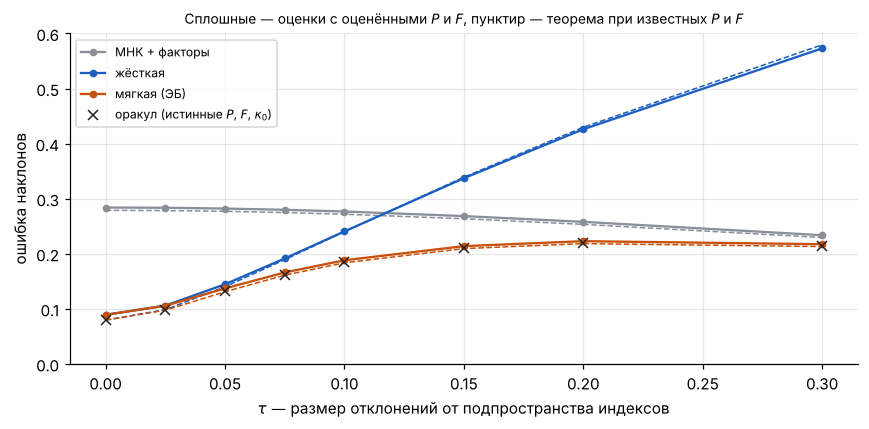

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.array(TAUS)
for col, th, c, lab in [('МНК+ф.', 'теория: МНК', C_OLS, 'МНК + факторы'), ('жёсткая', 'теория: жёсткая', C_HARD, 'жёсткая'),
                        ('мягкая (ЭБ)', 'теория: мягкая', C_SOFT, 'мягкая (ЭБ)')]:
    ax.plot(x, tab_tau[th], color=c, lw=1, ls='--')
    ax.plot(x, tab_tau[col], 'o-', color=c, ms=4, label=lab)
ax.plot(x, tab_tau['оракул'], 'x', color=C_OR, label='оракул (истинные $P$, $F$, $\\kappa_0$)')
ax.set_xlabel('$\\tau$ — размер отклонений от подпространства индексов'); ax.set_ylabel('ошибка наклонов')
ax.set_title('Сплошные — оценки с оценёнными $P$ и $F$, пунктир — теорема при известных $P$ и $F$', fontsize=9)
ax.set_ylim(0, 0.6); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Мягкая оценка не хуже лучшей из двух крайних при всех $\tau$. При $\tau=0$ она совпадает с жёсткой ($\hat\kappa=\infty$ в 14 из 20 повторений), при больших $\tau$ обгоняет МНК. Сильнее всего она выигрывает там, где крайние близки: при $\tau=0.1$ ошибка 0.188 против 0.241 у жёсткой и 0.277 у МНК, на 22% меньше лучшей из них. Пунктир теоремы почти совпадает с оракулом, а сама оценка с оценёнными $P$, $F$ и $\kappa$ уступает оракулу лишь на 1.5–4% при $\tau\ge0.05$. Эмпирический Байес немного завышает $\kappa$ (около 10%): оценённое подпространство подстраивается под наклоны и забирает часть отклонений.

## 3. Синтетика: длина ряда $T$

Фиксируем $\tau=0.1$ и меняем $T$. По части (c) теоремы дисперсия МНК $V\propto1/T$ убывает, а смещение жёсткой оценки $D$ от $T$ не зависит, поэтому при росте $T$ жёсткая оценка должна проиграть МНК.

In [8]:
t0 = time.time()
TS = [50, 100, 200, 400]
res_T = {T_: pd.DataFrame([one(0.1, s, T=T_) for s in range(20)]) for T_ in TS}
print(f'время: {time.time() - t0:.0f} с')
tab_T = pd.DataFrame({T_: r[['ols', 'hard', 'soft', 'oracle', 'th_soft']].mean() for T_, r in res_T.items()}).T
tab_T['kappa/kappa0 (медиана)'] = [r['k_ratio'].median() for r in res_T.values()]
tab_T.index.name = 'T'
tab_T.columns = ['МНК+ф.', 'жёсткая', 'мягкая (ЭБ)', 'оракул', 'теория: мягкая', 'kappa/kappa0 (медиана)']
tab_T.round(3)

время: 32 с


,МНК+ф.,жёсткая,мягкая (ЭБ),оракул,теория: мягкая,kappa/kappa0 (медиана)
T,,,,,,
50,0.484,0.260,0.232,0.225,0.225,1.005
100,0.277,0.241,0.188,0.184,0.184,1.102
200,0.181,0.231,0.147,0.145,0.145,1.064
400,0.123,0.226,0.110,0.109,0.110,1.061


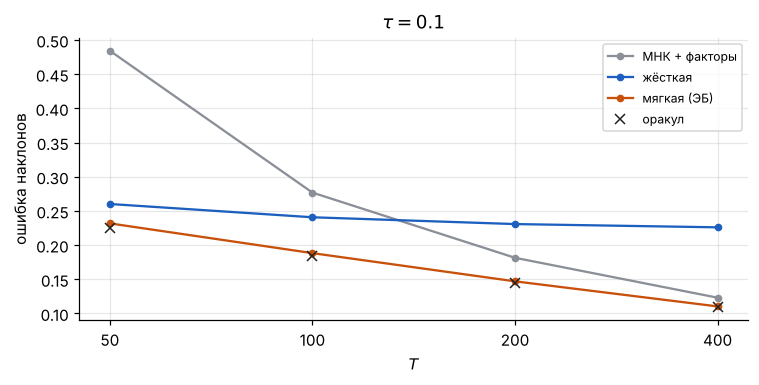

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for col, c, lab in [('МНК+ф.', C_OLS, 'МНК + факторы'), ('жёсткая', C_HARD, 'жёсткая'), ('мягкая (ЭБ)', C_SOFT, 'мягкая (ЭБ)')]:
    ax.plot(TS, tab_T[col], 'o-', color=c, ms=4, label=lab)
ax.plot(TS, tab_T['оракул'], 'x', color=C_OR, label='оракул')
ax.set_xscale('log'); ax.minorticks_off(); ax.set_xticks(TS); ax.set_xticklabels(TS)
ax.set_xlabel('$T$'); ax.set_ylabel('ошибка наклонов'); ax.set_title('$\\tau=0.1$'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Ошибка жёсткой оценки почти не уменьшается с ростом $T$: это смещение из-за отброшенных отклонений. МНК убывает как $1/\sqrt T$ и при $T\ge200$ обгоняет жёсткую. Мягкая оценка лучшая при всех $T$, так что выбирать между крайними заранее не нужно. Это ровно то, что говорит часть (c): $V\propto1/T$, а $D$ от $T$ не зависит.

## 4. Монотонность алгоритма

Блочный спуск: наклоны по формуле $\hat b_i(\kappa)$ → индексы $P$ как главные оси $\hat{\mathcal B}$ → факторы по остаткам. Каждый шаг точно минимизирует $S_\kappa$ по своему блоку, поэтому $S_\kappa$ не возрастает.

S_kappa не возрастает во всех 240 запусках: True
итераций: медиана 13, максимум 71


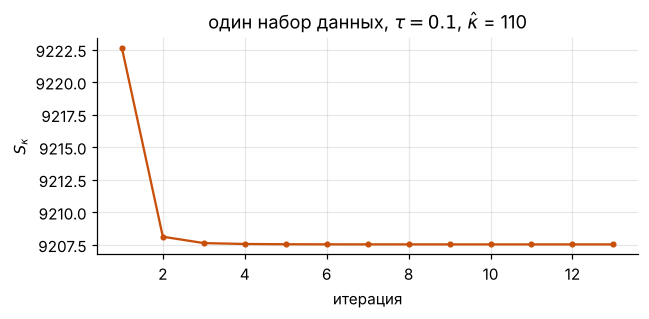

In [10]:
allr = pd.concat(list(res_tau.values()) + list(res_T.values()))
print(f"S_kappa не возрастает во всех {len(allr)} запусках: {bool(allr['mono'].all())}")
print(f"итераций: медиана {allr.loc[allr['iters'] > 0, 'iters'].median():.0f}, максимум {allr['iters'].max()}")
D = ps.make_soft_data(0.1, seed=3); Hh = pf.fit(D['Y'], D['X'], 2, 2); Sft = ps.fit_soft(D['Y'], D['X'], 2, 2, 'eb', hard=Hh)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, Sft['iters'] + 1), Sft['hist'], 'o-', color=C_SOFT, ms=3)
ax.set_xlabel('итерация'); ax.set_ylabel('$S_\\kappa$'); ax.set_title(f"один набор данных, $\\tau=0.1$, $\\hat\\kappa$ = {Sft['kappa']:.0f}")
plt.tight_layout(); plt.show()

## 5. Данные Dominick's

Та же схема, что в ноутбуке `realnye_dannye_orangejuice.ipynb`: 11 марок, обучение на первых 97 неделях, тест на последних 24 неделях по отложенной половине магазинов, сценарий «с текущей неделей», 5 разбиений. Числа $m$ и $r$ для жёсткой оценки выбираются по валидации, как раньше. Мягкая оценка берёт те же $m$ и $r$ и:
- **мягкая (ЭБ)** — $\kappa$ эмпирическим Байесом, без настройки;
- **мягкая (валидация)** — $\kappa=c\cdot\hat\kappa_{\rm ЭБ}$, где $c\in\{0,\tfrac19,\tfrac13,1,3,9,\infty\}$ выбирается на том же валидационном периоде (на отдельных случайных разбиениях магазинов).

**Как получить данные.** В R: `library(bayesm); data(orangeJuice); write.csv(orangeJuice$yx, "orangejuice_yx.csv", row.names = FALSE)`, затем положить файл рядом с ноутбуком.

In [11]:
BRANDS = ['Tropicana Premium 64', 'Tropicana Premium 96', "Florida's Natural 64", 'Tropicana 64', 'Minute Maid 64',
          'Minute Maid 96', 'Citrus Hill 64', 'Tree Fresh 64', 'Florida Gold 64', 'Dominicks 64', 'Dominicks 128']
RAW = pd.read_csv('orangejuice_yx.csv')


def load_panel(brand):
    g = RAW[RAW.brand == brand]
    stores = np.sort(g.store.unique()); weeks = np.sort(RAW.week.unique())
    si = {s: k for k, s in enumerate(stores)}; wi = {w: k for k, w in enumerate(weeks)}
    n, T = len(stores), len(weeks)
    Y = np.zeros((n, T)); X = np.zeros((n, T, 13)); mask = np.zeros((n, T), bool)
    i = g.store.map(si).values; t = g.week.map(wi).values
    Y[i, t] = g.logmove.values
    X[i, t, :11] = np.log(g[[f'price{k}' for k in range(1, 12)]].values)
    X[i, t, 11] = g.deal.values; X[i, t, 12] = g.feat.values
    mask[i, t] = True
    return Y, X, mask


MULTS = [0.0, 1 / 9, 1 / 3, 1.0, 3.0, 9.0, np.inf]


def predict(model, kind, X, Y, obs_cells):
    base = np.einsum('itd,id->it', X, model['B']) + model['c'][:, None]
    comp = np.zeros_like(base); R = Y - base
    for t in np.where(obs_cells.any(0))[0]:
        o = obs_cells[:, t]
        if kind == 'factors' and model['G'].shape[1] > 0:
            comp[:, t] = model['G'] @ np.linalg.lstsq(model['G'][o], R[o, t], rcond=None)[0]
        elif kind == 'twoway':
            comp[:, t] = R[o, t].mean()
    return base + comp, base


def fit_spec(Yt, Xt, mt, kind, m, r, cache):
    if kind == 'twoway':
        return pm.fit_twoway(Yt, Xt, mt)
    if (m, r) not in cache:
        cache[(m, r)] = pm.fit(Yt, Xt, mt, m=m, r=r)
    if kind == 'lr':
        return cache[(m, r)]
    H = cache[(m, r)]
    if kind == 'soft_eb':
        return ps.fit_soft_miss(Yt, Xt, mt, m, r, 'eb', hard=H)
    if kind == 'soft_split':                                  # tau^2 по двум половинам ряда
        s2 = ps.fit_soft_miss(Yt, Xt, mt, m, r, np.inf, hard=H)['s2']
        t2 = ps.tau2_split(Xt, Yt, mt, H['F'], H['P'])
        return dict(ps.fit_soft_miss(Yt, Xt, mt, m, r, s2 / t2 if t2 > 0 else np.inf, hard=H), tau2_split=t2)
    mult = kind[1]                                            # ('soft', c): kappa = c * kappa_EB
    eb = ps.fit_soft_miss(Yt, Xt, mt, m, r, np.inf, hard=H)['kappa_eb']
    return ps.fit_soft_miss(Yt, Xt, mt, m, r, mult * eb if mult > 0 else 0.0, hard=H)


def evaluate(Y, X, mask, T_fit, T_end, spec, nsplit, rng):
    cache = {}; fitted = {}
    for name, (kind, m, r) in spec.items():
        fitted[name] = fit_spec(Y[:, :T_fit], X[:, :T_fit], mask[:, :T_fit], kind, m, r, cache)
    out = {k: [] for k in spec}
    n = Y.shape[0]
    for s in range(nsplit):
        held = rng.random(n) < 0.5
        obs = mask.copy(); obs[:, :T_fit] = False; obs[:, T_end:] = False
        test_cells = (obs & held[:, None])[:, :T_end]; obs_cells = (obs & ~held[:, None])[:, :T_end]
        for name, (kind, m, r) in spec.items():
            pf_, _ = predict(fitted[name], 'twoway' if kind == 'twoway' else ('factors' if r else 'none'),
                             X[:, :T_end], Y[:, :T_end], obs_cells)
            out[name].append(np.sqrt(np.mean((Y[:, :T_end] - pf_)[test_cells] ** 2)))
    return {k: float(np.mean(v)) for k, v in out.items()}, fitted


def diagnostics(Yt, Xt, mt, H, Sft, test):
    # что предсказывает теорема (часть b) с оценками ЭБ, автокорреляция остатков и tau^2 со своей sigma_i у магазина
    d = Xt.shape[2]; P = H['P']; Q = ps.complement(P); r = H['F'].shape[1]
    G, Z, yy, no = ps.unit_stats_y(Xt, Yt, mt, H['F']); G = G + 1e-8 * np.eye(d)
    s2, t2, kap = Sft['s2'], Sft['tau2'], Sft['kappa']
    def pred_risk(kappa):                                     # E (b_hat - b)^T (G_i / T_i) (b_hat - b), среднее по магазинам
        tot = 0.0
        for Gi, Ti in zip(G, no):
            K = ps.shrink_matrix(Gi, P, kappa); M = K @ Gi - np.eye(d)
            tot += np.trace(Gi / Ti @ (t2 * M @ Q @ M.T + s2 * K @ Gi @ K.T))
        return tot / len(G)
    r_ols, r_hard, r_soft = pred_risk(0.0), pred_risk(np.inf), pred_risk(kap)
    mse = test['жёсткая'] ** 2
    Bo = np.linalg.solve(G, Z[..., None])[..., 0]
    s2_i = (yy - np.einsum('ia,ia->i', Z, Bo)) / (no - d - 1 - r)
    t2_unit = max(np.mean(np.sum((Bo @ Q) ** 2, 1) - s2_i * np.einsum('ab,iba->i', Q, np.linalg.inv(G))), 0) / (d - P.shape[0])
    R = pm.residuals(Yt, Xt, Bo); ac = []
    for i in range(len(R)):
        o = mt[i]; Qh = np.linalg.qr(np.column_stack([np.ones(o.sum()), H['F'][o]]))[0]
        e = R[i, o] - Qh @ (Qh.T @ R[i, o]); ac.append(np.corrcoef(e[:-1], e[1:])[0, 1])
    return dict(exp_soft=100 * (np.sqrt(mse - r_hard + r_soft) / np.sqrt(mse) - 1),
                exp_ols=100 * (np.sqrt(mse - r_hard + r_ols) / np.sqrt(mse) - 1),
                fact_soft=100 * (test['мягкая (ЭБ)'] / test['жёсткая'] - 1),
                fact_ols=100 * (test['МНК + факторы'] / test['жёсткая'] - 1),
                tau2_unit=t2_unit, ac=float(np.nanmedian(ac)))


def run_brand(b, n_test=24, n_val=16, splits=5, grid_m=(1, 2, 3, 12), grid_r=(0, 1, 2, 3)):
    Y, X, mask = load_panel(b); X = X[:, :, :12]; n, T, d = X.shape
    rng = np.random.default_rng(b)                            # те же разбиения, что в основном ноутбуке
    T_train = T - n_test
    spec = {f'm{m}_r{r}': ('lr', m, r) for m in grid_m for r in grid_r}
    val, _ = evaluate(Y, X, mask, T_train - n_val, T_train, spec, 3, rng)
    best = min(val, key=val.get)
    best_ols = min([k for k in val if k.startswith('m12_')], key=val.get)
    m_b, r_b = spec[best][1], spec[best][2]
    sspec = {f'k{j}': (('soft', mu), m_b, r_b) for j, mu in enumerate(MULTS)}
    val_soft, _ = evaluate(Y, X, mask, T_train - n_val, T_train, sspec, 3, np.random.default_rng(1000 + b))
    mult = MULTS[int(min(val_soft, key=val_soft.get)[1:])]
    final = {'МНК + факторы': ('lr', d, spec[best_ols][2]),
             'жёсткая': ('lr', m_b, r_b),
             'мягкая (ЭБ)': ('soft_eb', m_b, r_b),
             'мягкая (валидация)': (('soft', mult), m_b, r_b),
             'мягкая (половины)': ('soft_split', m_b, r_b)}
    test, fitted = evaluate(Y, X, mask, T_train, T, final, splits, rng)
    Sft, H, O = fitted['мягкая (ЭБ)'], fitted['жёсткая'], fitted['МНК + факторы']
    diag = diagnostics(Y[:, :T_train], X[:, :T_train], mask[:, :T_train], H, Sft, test)
    return dict(brand=b, m=m_b, r=r_b, mult=mult, test=test, kappa=Sft['kappa'], tau=np.sqrt(Sft['tau2']),
                tau2_split=fitted['мягкая (половины)']['tau2_split'], diag=diag,
                share=Sft['share'], iters=Sft['iters'],
                shift=np.linalg.norm(Sft['B'] - H['B']) / np.linalg.norm(H['B']),
                own=[np.median(M['B'][:, b - 1]) for M in (O, H, Sft)], sd=[np.std(M['B'][:, b - 1]) for M in (O, H, Sft)])

t0 = time.time()
results = [run_brand(b) for b in range(1, 12)]
print(f'время: {time.time() - t0:.0f} с')

время: 707 с


In [12]:
names = ['МНК + факторы', 'жёсткая', 'мягкая (ЭБ)', 'мягкая (валидация)', 'мягкая (половины)']
fmt_c = lambda c: '∞' if np.isinf(c) else f'{c:.2g}'
tab = pd.DataFrame([[BRANDS[R['brand'] - 1], R['m'], R['r']] + [R['test'][k] for k in names] + [fmt_c(R['mult'])] for R in results],
                   columns=['марка', 'm', 'r'] + names + ['c (валидация)']).set_index('марка')
tab.loc['среднее'] = [np.nan, np.nan] + [tab[k].mean() for k in names] + ['']
print('RMSE логарифма продаж отложенных магазинов, сценарий «с текущей неделей»')
display(tab.round(4))
for k in ['мягкая (ЭБ)', 'мягкая (валидация)', 'мягкая (половины)']:
    dlt = np.array([R['test'][k] / R['test']['жёсткая'] - 1 for R in results])
    print(f'{k} против жёсткой: лучше в {np.sum(dlt < -1e-4)} марках, хуже в {np.sum(dlt > 1e-4)}, '
          f'среднее изменение RMSE {100 * dlt.mean():+.2f}%')

RMSE логарифма продаж отложенных магазинов, сценарий «с текущей неделей»


,m,r,МНК + факторы,жёсткая,мягкая (ЭБ),мягкая (валидация),мягкая (половины),c (валидация)
марка,,,,,,,,
Tropicana Premium 64,2.0,1.0,0.2774,0.2600,0.2604,0.2587,0.2600,3
Tropicana Premium 96,1.0,3.0,0.2173,0.2028,0.2018,0.2022,0.2028,3
Florida's Natural 64,1.0,2.0,0.3852,0.3599,0.3465,0.3599,0.3599,∞
Tropicana 64,1.0,1.0,0.5324,0.4996,0.5015,0.4996,0.4996,∞
Minute Maid 64,1.0,2.0,0.3179,0.2973,0.2983,0.3045,0.2973,0.11
Minute Maid 96,2.0,3.0,0.2692,0.2496,0.2496,0.2496,0.2496,0.11
Citrus Hill 64,1.0,2.0,0.3741,0.3429,0.3541,0.3446,0.3550,9
Tree Fresh 64,1.0,1.0,0.3651,0.3401,0.3408,0.3401,0.3552,9
Florida Gold 64,2.0,1.0,0.6754,0.6399,0.6558,0.6777,0.6399,0.11


мягкая (ЭБ) против жёсткой: лучше в 2 марках, хуже в 8, среднее изменение RMSE +0.34%
мягкая (валидация) против жёсткой: лучше в 3 марках, хуже в 4, среднее изменение RMSE +0.74%
мягкая (половины) против жёсткой: лучше в 0 марках, хуже в 2, среднее изменение RMSE +0.72%


In [13]:
diag = pd.DataFrame([[BRANDS[R['brand'] - 1], R['kappa'], R['tau'], R['share'], R['shift'], R['iters']] + R['own'] + R['sd'] for R in results],
                    columns=['марка', 'kappa (ЭБ)', 'tau (ЭБ)', 'доля настоящих отклонений', 'сдвиг от жёсткой', 'итераций',
                             'медиана: МНК+ф.', 'медиана: жёсткая', 'медиана: мягкая', 'разброс: МНК+ф.', 'разброс: жёсткая', 'разброс: мягкая']).set_index('марка')
print('Эмпирический Байес и собственная эластичность по магазинам')
diag.round(3)

Эмпирический Байес и собственная эластичность по магазинам


,kappa (ЭБ),tau (ЭБ),доля настоящих отклонений,сдвиг от жёсткой,итераций,медиана: МНК+ф.,медиана: жёсткая,медиана: мягкая,разброс: МНК+ф.,разброс: жёсткая,разброс: мягкая
марка,,,,,,,,,,,
Tropicana Premium 64,3.129,0.129,0.235,0.267,175,-1.667,-1.745,-1.681,0.444,0.404,0.434
Tropicana Premium 96,8.880,0.055,0.090,0.122,141,-1.160,-0.973,-1.029,0.670,0.491,0.502
Florida's Natural 64,2.697,0.187,0.239,0.349,198,-2.400,-2.083,-2.352,0.624,0.682,0.607
Tropicana 64,1.811,0.234,0.320,0.432,187,-1.545,-1.560,-1.576,0.573,0.338,0.458
Minute Maid 64,7.359,0.094,0.104,0.148,200,-1.329,-1.274,-1.330,0.470,0.678,0.619
Minute Maid 96,inf,0.000,0.000,0.000,0,-2.019,-1.193,-1.193,0.764,0.640,0.640
Citrus Hill 64,1.125,0.262,0.421,0.529,200,-1.966,-1.676,-1.791,0.865,0.576,0.875
Tree Fresh 64,22.479,0.061,0.038,0.074,178,-1.596,-1.661,-1.649,0.759,0.585,0.628
Florida Gold 64,3.239,0.335,0.223,0.271,158,-2.890,-2.391,-2.338,1.135,0.877,0.884


**На Dominick's результат отрицательный.** Мягкая оценка прогноз не улучшает: средний RMSE 0.355 (эмпирический Байес), 0.357 (валидация) и 0.356 (половины) против 0.353 у жёсткой. Вариант с эмпирическим Байесом лучше жёсткого в 2 марках и хуже в 8, но во всех марках лучше МНК с факторами. Медианы собственной эластичности у мягкой и жёсткой оценок в большинстве марок отличаются на 0.1–0.3, сильнее всего у Dominicks 64 (−1.10 против −0.60).

**Проверка: согласуются ли оценки эмпирического Байеса с прогнозом.** Если бы отклонения с оценённым $\hat\tau^2$ были настоящими, то по теореме (часть b) можно заранее посчитать, насколько изменится RMSE прогноза при переходе от жёсткой оценки к мягкой и к МНК. Для этого риск наклонов берётся в метрике прогноза, $\mathsf E(\hat b_i-b_i)^\top(G_i/T_i)(\hat b_i-b_i)$. Сравниваем это с фактическим изменением RMSE. Рядом — два возможных объяснения расхождения: автокорреляция остатков и разная дисперсия шума у магазинов ($\hat\tau^2$, пересчитанное со своей $\hat\sigma_i^2$ у каждого магазина). Последний столбец — $\hat\tau^2$ по двум половинам ряда.

In [14]:
chk = pd.DataFrame([[BRANDS[R['brand'] - 1], R['diag']['exp_soft'], R['diag']['fact_soft'], R['diag']['exp_ols'], R['diag']['fact_ols'],
                     R['diag']['ac'], R['tau'] ** 2, R['diag']['tau2_unit'], R['tau2_split']] for R in results],
                   columns=['марка', 'мягкая: ожид. %', 'мягкая: факт %', 'МНК+ф.: ожид. %', 'МНК+ф.: факт %',
                            'автокорр. остатков', 'tau^2 ЭБ', 'tau^2 ЭБ со своей sigma_i', 'tau^2 по половинам']).set_index('марка')
chk.loc['среднее'] = chk.mean()
chk.round(4)

,мягкая: ожид. %,мягкая: факт %,МНК+ф.: ожид. %,МНК+ф.: факт %,автокорр. остатков,tau^2 ЭБ,tau^2 ЭБ со своей sigma_i,tau^2 по половинам
марка,,,,,,,,
Tropicana Premium 64,-2.8093,0.1644,-0.2205,6.6953,0.0567,0.0167,0.0177,0.0000
Tropicana Premium 96,-0.4223,-0.4911,2.6449,7.1631,-0.0173,0.0030,0.0052,0.0000
Florida's Natural 64,-3.6628,-3.7224,-1.0826,7.0134,0.0518,0.0352,0.0320,0.0000
Tropicana 64,-3.1007,0.3887,-1.8661,6.5709,0.0787,0.0550,0.0528,0.0000
Minute Maid 64,-0.8354,0.3427,2.5140,6.9407,0.0655,0.0089,0.0121,0.0000
Minute Maid 96,0.0000,0.0000,2.7940,7.8804,0.0104,0.0000,0.0016,0.0000
Citrus Hill 64,-9.6473,3.2449,-7.8579,9.0933,0.0691,0.0687,0.0705,0.0965
Tree Fresh 64,-0.1925,0.2201,3.5627,7.3422,0.0652,0.0037,0.0088,0.1889
Florida Gold 64,-3.4404,2.4956,-0.4046,5.5566,0.1517,0.1124,0.1063,0.0000


Если бы оценённые эмпирическим Байесом отклонения были настоящими, мягкая оценка должна была бы улучшить RMSE в среднем на 2.5%, а МНК с факторами почти не уступать жёсткой (+0.2%). На деле мягкая хуже на 0.3%, а МНК — на 7.5%. Значит, разброс МНК-наклонов вне подпространства индексов — шум, причём больший, чем даёт формула $\sigma^2G_i^{-1}$. Автокорреляция остатков мала (около 0.06), а своя $\hat\sigma_i^2$ у каждого магазина почти не меняет $\hat\tau^2$, так что дело не в этом. Вероятные причины — ошибка оценки факторов и остаточная зависимость между магазинами. Оценка по половинам ряда, которой формула для дисперсии не нужна, даёт $\tau^2=0$ в 9 марках из 11: устойчивых во времени отклонений от малого ранга в этих данных нет.

## Итоги

1. **Теорема подтверждена численно:** формула риска, $\mathcal R'(0)<0$, оптимальное $\kappa_0=\sigma^2/\tau^2$, тождество Пифагора и изотропная формула $\sigma^2m/g+VD/(V+D)$.
2. **Синтетика:** мягкая оценка не хуже лучшей из крайних при любом размере отклонений и любом $T$, до 22% точнее жёсткой и всего на 1.5–4% хуже оракула. Алгоритм монотонен.
3. **Выбор $\kappa$:** обычный эмпирический Байес хорош, когда модель шума верна, но при автокорреляции или другой ошибке в дисперсии принимает шум за отклонения. Оценка по двум половинам ряда от этого защищена.
4. **Dominick's:** мягкая оценка прогноз не улучшает, а устойчивая оценка дисперсии отклонений равна нулю в 9 марках из 11. Для этих данных точный малый ранг адекватен, и мягкая модель служит его проверкой.